## Human In the Loop

Sometimes an agent should stop and ask a human before it continues (approval, missing info, expert input).

In LangGraph this works with:
- `interrupt()` - called inside a node/tool, it **pauses** the graph and sends a value to the human
- `checkpointer` (MemorySaver) - saves the graph state so it can be resumed later
- `Command(resume=...)` - sends the human's answer back and **resumes** the graph from where it paused

In [1]:
from typing import Annotated

from typing_extensions import TypedDict

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.checkpoint.memory import MemorySaver
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.types import Command, interrupt
from langchain_core.tools import tool

In [2]:
from langchain_groq import ChatGroq

llm=ChatGroq(model="openai/gpt-oss-120b")

In [3]:
class State(TypedDict):
    messages:Annotated[list,add_messages]

### Human assistance tool
When the LLM calls this tool, `interrupt()` pauses the graph and hands the `query` to the human.
Whatever the human sends back with `Command(resume=...)` becomes the return value of `interrupt()`.

In [4]:
@tool
def human_assistance(query: str) -> str:
    """Request assistance from a human."""
    human_response = interrupt({"query": query})
    return human_response["data"]

tools=[human_assistance]
llm_with_tools=llm.bind_tools(tools)

In [5]:
## Node definition
def chatbot(state:State):
    message=llm_with_tools.invoke(state["messages"])
    # On resume the tool node re-runs, so allow only one tool call
    # to avoid repeating any tool invocations
    assert len(message.tool_calls) <= 1
    return {"messages":[message]}

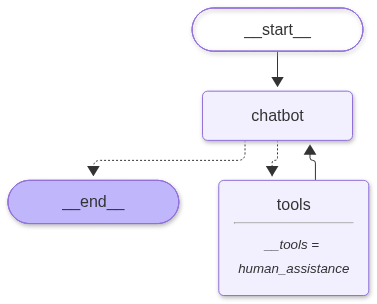

In [6]:
## Graph
graph_builder=StateGraph(State)
graph_builder.add_node("chatbot",chatbot)
graph_builder.add_node("tools",ToolNode(tools))

## Edges
graph_builder.add_edge(START,"chatbot")
graph_builder.add_conditional_edges("chatbot",tools_condition)
graph_builder.add_edge("tools","chatbot")

## Checkpointer is required for interrupt - the paused state is saved here
memory=MemorySaver()
graph=graph_builder.compile(checkpointer=memory)

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

### Step 1: Run until the graph pauses
The LLM calls `human_assistance`, and the graph stops at `interrupt()`.

In [7]:
user_input="I need some expert guidance and assistance for building an AI agent. Could you request assistance for me?"
config={"configurable":{"thread_id":"1"}}

events=graph.stream({"messages":user_input},config,stream_mode="values")
for event in events:
    if "messages" in event:
        event["messages"][-1].pretty_print()

================================ Human Message =================================

I need some expert guidance and assistance for building an AI agent. Could you request assistance for me?
================================== Ai Message ==================================
Tool Calls:
  human_assistance (fc_b650c855-7c8e-4f03-9509-0828a02f204e)
 Call ID: fc_b650c855-7c8e-4f03-9509-0828a02f204e
  Args:
    query: User requests expert guidance and assistance for building an AI agent.
================================== Ai Message ==================================
Tool Calls:
  human_assistance (fc_b650c855-7c8e-4f03-9509-0828a02f204e)
 Call ID: fc_b650c855-7c8e-4f03-9509-0828a02f204e
  Args:
    query: User requests expert guidance and assistance for building an AI agent.


In [8]:
## The graph is paused - next node to run is "tools"
snapshot=graph.get_state(config)
snapshot.next

('tools',)

### Step 2: Human responds and the graph resumes
`Command(resume=...)` passes the human's answer into `interrupt()`, the tool returns it, and the chatbot continues.

In [9]:
human_response=(
    "We, the experts are here to help! We'd recommend you check out LangGraph to build your agent."
    " It's much more reliable and extensible than simple autonomous agents."
)

human_command=Command(resume={"data":human_response})

events=graph.stream(human_command,config,stream_mode="values")
for event in events:
    if "messages" in event:
        event["messages"][-1].pretty_print()

================================== Ai Message ==================================
Tool Calls:
  human_assistance (fc_b650c855-7c8e-4f03-9509-0828a02f204e)
 Call ID: fc_b650c855-7c8e-4f03-9509-0828a02f204e
  Args:
    query: User requests expert guidance and assistance for building an AI agent.
================================= Tool Message =================================
Name: human_assistance

We, the experts are here to help! We'd recommend you check out LangGraph to build your agent. It's much more reliable and extensible than simple autonomous agents.
================================== Ai Message ==================================

Got it! It sounds like you’re ready to dive into building a robust AI agent. Here’s a quick roadmap to get you started, along with some pointers you can explore right away:

---

## 1️⃣ Clarify Your Agent’s Purpose & Scope
- **What problem are you solving?** (e.g., customer support, data extraction, autonomous research)
- **What inputs and outputs will 